In [1]:
import pandas as pd
import requests as rq
import json 
import matplotlib.pyplot as plt
import seaborn as sns

### Сбор данных

In [3]:
# создаем функцию для загрузки данных с World Bank
def get_from_wb(country_codes, indicator_code, start = 2010, end = 2023):
    countries_str = ";".join(country_codes)
    url1 = f"https://api.worldbank.org/v2/country/{countries_str}/indicator/{indicator_code}"
    parametrs = {                                     
        "format": "json",
        "date": f"{start}:{end}",
        "per_page": 10000}
    
    # запрашиваем данные и возвращаем пустое значение, если оно не найдено
    try:
        re1 = rq.get(url1, params = parametrs, timeout = 10)
        data1 = json.loads(re1.text)
    except (rq.RequestException, ValueError):
        return pd.DataFrame()
        
    result = []
    for i in data1[1]:
        result.append({
        "Country": i["country"]["value"],
        "Year": int(i["date"]),
        "Value": i["value"]})
    return pd.DataFrame(result)

# создаем функцию для создания списка стран
def get_countries():
    url2 = "https://api.worldbank.org/v2/country?format=json&per_page=1000"

    # запрашиваем данные и возвращаем пустое значение, если оно не найдено
    try:
        re2 = rq.get(url2, timeout = 10)
        data2 = json.loads(re2.text)
    except (rq.RequestException, ValueError):
        return pd.DataFrame()
    
    countries = []
    for j in data2[1]:
        countries.append({
        "ID": j["id"],
        "Income_level": j["incomeLevel"]["id"]})
    return pd.DataFrame(countries)

# создаем выборку (по 10 стран из каждой группы дохода)
all_countries = get_countries()
groups = ["HIC", "UMC", "LMC", "LIC"]
selected_countries = []

for k in groups:
    group_countries = all_countries[all_countries["Income_level"] == k]["ID"].tolist()
    n = min(10, len(group_countries))
    selected_countries.extend(group_countries[:n])

# выбираем индикаторы
indicators = {
    "NY.GDP.MKTP.KD.ZG": "GDP_growth",           # Рост ВВП (%)
    "NY.GDP.PCAP.CD": "GDP_per_capita",          # ВВП на душу ($)
    "FP.CPI.TOTL.ZG": "Inflation",               # Инфляция (ИПЦ, %)
    "SL.UEM.TOTL.ZS": "Unemployment",            # Безработица (%)
    "BN.CAB.XOKA.GD.ZS": "Current_account",      # Сальдо счета текущих операций (% ВВП)
    "GC.XPN.TOTL.GD.ZS": "Gov_expenditure",      # Государственные расходы (% ВВП)
    "GC.REV.XGRT.GD.ZS": "Gov_revenue",          # Государственные доходы (% ВВП)
    "CC.EST": "Control_of_Corruption",           # Контроль коррупции
    "RL.EST": "Rule_of_Law",                     # Верховенство права
    "PV.EST": "Political_Stability",             # Политическая стабильность
    "GE.EST": "Government_Effectiveness",        # Эффективность правительства
    "RQ.EST": "Regulatory_Quality",              # Качество регулирования
    "VA.EST": "Voice_and_Accountability"         # Право голоса и подотчетность
}

# собираем данные по каждому индикатору
data = []
for code, name in indicators.items():
    dataframe = get_from_wb(selected_countries, code, 2010, 2023)
    if not dataframe.empty:
        dataframe["Indicator"] = name
        data.append(dataframe)

# создаем итоговый датафрейм
df = pd.concat(data, ignore_index = True)
df = df.pivot_table(
    index = ["Country", "Year"],
    columns = "Indicator",
    values = "Value").reset_index()
df = df.sort_values(by = ["Country", "Year"])

### Очистка данных

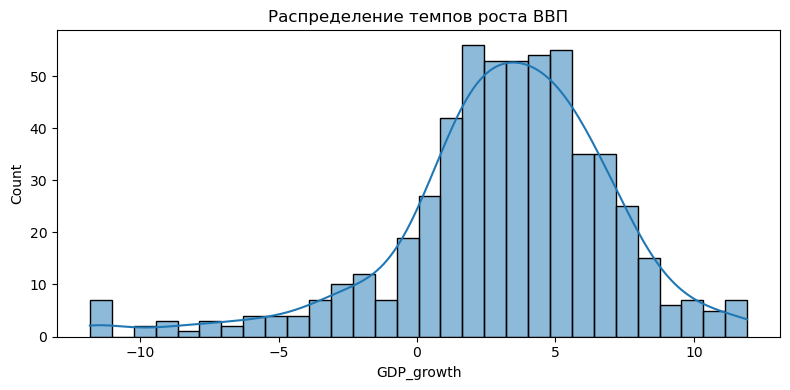

Данные загружены в файл


In [5]:
# Работа с типами значений в столбцах, где необходимо числовое значение
num_cs = [i for i in df.columns if i != "Country"]
for i in num_cs:
    df[i] = pd.to_numeric(df[i], errors = "coerce")
df["Year"] = df["Year"].astype("Int64")

# Удаление технических кодов при наличии
df[num_cs] = df[num_cs].replace([9999, -9999], pd.NA)

# Удаление дубликатов
df = df.drop_duplicates(subset = ["Country", "Year"], keep = "first")

# Удаление строк, если country или year пустой
df = df.dropna(subset = ["Country", "Year"])

# По всем остальным переменным в пропуски вставляется либо
# (1) медиана по стране
# (2) медиана по году
# (3) общая медиана по переменной
num_css = [i for i in df.columns if i not in ["Country", "Year"]]
for i in num_css:
    df[i] = df[i].fillna(df.groupby("Country")[i].transform("median")) 
    df[i] = df[i].fillna(df.groupby("Year")[i].transform("median"))
    df[i] = df[i].fillna(df[i].median())

# Выявление выбросов для составления списка для винсоризации
winsor = []

for i in num_css:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3 - q1
    if iqr <= 0:
        continue
    low_iqr = q1 - 1.5 * iqr
    high_iqr = q3 + 1.5 * iqr
    outlier = (df[i] < low_iqr) | (df[i] > high_iqr)
    outlier_share = outlier.sum() / len(df)
    if outlier_share > 0.01:
        winsor.append(i)

for i in winsor:
    low = df[i].quantile(0.01)
    high = df[i].quantile(0.99)
    df[i] = df[i].clip(lower = low, upper = high)

# График распределения темпов роста ВВП
plt.figure(figsize = (8, 4))
sns.histplot(df["GDP_growth"], bins = 30, kde = True)
plt.title("Распределение темпов роста ВВП")
plt.tight_layout()
plt.show()

df.to_csv("Data_project.csv", index = False)
print("Данные загружены в файл")

### Построение модели

In [7]:
from sklearn import preprocessing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def gdp_converter(number): #преоьразовываем джи ди пи в бинарный 
    if number <= 0:
        return(0)
    else:
        return(1)

Y = df["GDP_growth"].apply(gdp_converter) #применяем эту функцию 


X = pd.get_dummies(df, columns = ["Year", "Country"])
X = X.drop(columns = ["GDP_growth"])


min_max_scaler = preprocessing.MinMaxScaler()  #нормализуем данные 
X_minmax = min_max_scaler.fit_transform(X)


X_train, X_test, Y_train, Y_test = train_test_split(X_minmax, Y, test_size = 0.2, stratify = Y)


model = LinearRegression()
model.fit(X_train, Y_train)


answer = model.predict(X_test) #делаем предсказание на тестовых данных

spisok = []
for i in answer:   #так как предсказания выдаются от 0 до 1 , а нам надо сравнить их с правильными ответами (== 0 или 1) , нам надо их привести к 0 или 1 
    if i < 0.5:  # 0.5 == стандартный порог для бинарных задач
        spisok.append(0)
    else:
        spisok.append(1)

accuracy_score(Y_test, spisok)

0.8839285714285714

Делаем те же действия , но с логистической моделью, чтобы выяснить, точность какой модели выше

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


X_train, X_test, y_train, y_test = train_test_split(
    X_minmax, Y, test_size=0.2, random_state=42 , stratify=Y
)

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("accuracy:", accuracy_score(y_test, y_pred))
print("score:", model.score(X_test, y_test))  
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.8660714285714286
score: 0.8660714285714286
[[ 5 12]
 [ 3 92]]
              precision    recall  f1-score   support

           0       0.62      0.29      0.40        17
           1       0.88      0.97      0.92        95

    accuracy                           0.87       112
   macro avg       0.75      0.63      0.66       112
weighted avg       0.85      0.87      0.84       112



### Визуализация